# Intro

* How to setup a pretraining procedure in PyTorch
* That even very simple models with little and limited training quickly learn structure
* A quirk in Python text printing and how to fix it

# Imports

In [19]:
import numpy as np
import requests
import matplotlib.pyplot as plt

# pytorch stuff
from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn
from torch.nn import functional as F

# vector plots
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

In [20]:
# GPT-2's tokenizer
from transformers import GPT2Tokenizer
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

In [21]:
# use the GPU for speed
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Hyperparameters

In [22]:
seq_len = 8
stride  = 2
embed_dim = 2**6
batch_size = 64
n_vocab = tokenizer.vocab_size

# Get Data

In [23]:
# tokenize the text and make it a tensor
text = requests.get('https://www.gutenberg.org/files/35/35-0.txt').text
tm_tokens = torch.tensor(tokenizer.encode(text))
len(tm_tokens)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (45295 > 1024). Running this sequence through the model will result in indexing errors


45295

# DataLoader

In [24]:
class TokenDataset(Dataset):
  def __init__(self, tokens, seq_len=8, stride=4):

    # initialize
    self.inputs  = []
    self.targets = []

    # overlapping sequences of seq_len
    for i in range(0, len(tokens)-seq_len, stride):

      # get c tokens and append to the lists
      self.inputs.append( tokens[i   : i+seq_len])
      self.targets.append(tokens[i+1 : i+seq_len+1])

  def __len__(self):
    return len(self.inputs)

  def __getitem__(self, idx):
    return self.inputs[idx], self.targets[idx]

In [25]:
token_dataset    = TokenDataset(tm_tokens, seq_len, stride)
token_dataloader = DataLoader(token_dataset, batch_size = batch_size, shuffle = True)

x,y=next(iter(token_dataloader))
x[:10], y[:10]

(tensor([[   13,   775,   389,  1464,  1972,  1497,   422,   262],
         [  355,   852,   257,   845,  4950,   290, 44363,  7185],
         [ 1392,   625,   262,   880,    12, 14775,   198, 11246],
         [  314,   750,   407,  1254,  3338,   422,   511, 43732],
         [   77,  6749, 39011,   355,   314,  3804,   832,    11],
         [  262,  1334,   286,   514, 22211,   564,   250, 10262],
         [34203,  1740, 23185,   400,  1211,    13, 12197,   428],
         [  286,   262,   198, 18223,  6340,  2114, 38745,   546],
         [   82,  3649, 31887,   507,   198,    67,  1809,   616],
         [  550,  9292,    13,  1406,    11,  2427,   286, 13092]]),
 tensor([[  775,   389,  1464,  1972,  1497,   422,   262,  1944],
         [  852,   257,   845,  4950,   290, 44363,  7185,    11],
         [  625,   262,   880,    12, 14775,   198, 11246,  4919],
         [  750,   407,  1254,  3338,   422,   511, 43732,   198],
         [ 6749, 39011,   355,   314,  3804,   832,    11,  

# Model

In [26]:
# Model
class Model(nn.Module):
  def __init__(self):
    super().__init__()

    self.embedding = nn.Embedding(n_vocab, embed_dim)
    self.gelu      = nn.GELU()
    self.linear    = nn.Linear(embed_dim, n_vocab)

  def forward(self, x):
    x = self.embedding(x)
    x = self.gelu(x)
    x = self.linear(x)
    return F.log_softmax(x, dim = -1)

  def generate(self, tok_x, n_tok_predict = 30):

    for i in range(n_tok_predict):
      output   = self(tok_x)
      logits   = output[:,-1,:] # [B, T, N_VOCAB]
      probs    = torch.exp(logits)
      next_tok = torch.multinomial(probs, num_samples = 1)
      tok_x = torch.cat((tok_x, next_tok), dim = 1)

    return tok_x

# Check Model

In [27]:
model = Model()
X, y = token_dataset[4]
out = model(X)[0]

print(X.shape)
print(y.shape)
print(out.shape)

torch.Size([8])
torch.Size([8])
torch.Size([50257])


In [28]:
torch.sum(torch.exp(out)).item()

1.000000238418579

In [29]:
print(X)
print(y)
print(torch.argmax(out))

tensor([ 1677, 13246,    38,   412, 39453,  3439, 17202,   628])
tensor([13246,    38,   412, 39453,  3439, 17202,   628,   628])
tensor(29679)


# Prepare for training

In [30]:
# push the model to the GPU
model = model.to(device)

In [31]:
# create the loss and optimizer functions
loss_function = nn.NLLLoss().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr = 0.001, weight_decay = 0.01)

In [32]:
# Chec loss function with sizes
X, y = next(iter(token_dataloader))
log_probs = model(X.to(device))

In [33]:
log_probs[:,:-1,:].shape, y[:,1:].shape

(torch.Size([64, 7, 50257]), torch.Size([64, 7]))

In [36]:
# flatten to [batch*token, vocab]
log_probs_flat = log_probs[:,:-1,:].reshape(-1, log_probs.shape[-1])

# flatten to a vector
y_flat = y[:,1:].reshape(-1)

In [37]:
log_probs_flat.shape, y_flat.shape

(torch.Size([448, 50257]), torch.Size([448]))

In [ ]:
print(f'Model input is size:   {X.shape}')
print(f'Model output is size:  {log_probs.shape}')
print(f'Target tokens is size: {y.shape}')


loss = loss_function(log_probs_flat,y_flat.to(device))
print('\nLoss:',loss)

In [ ]:
# some model generated text (compare with post-training)

# needs to be a tensor with one batch
start_toks  = torch.tensor(tokenizer.encode('I thought the Eloi would be smarter than')).unsqueeze(0)

# text generation
Y = model.generate(start_toks.to(device))
print(tokenizer.decode(Y[0].tolist()))

# Training Loop

In [ ]:
num_epochs = 25
total_loss = np.zeros(num_epochs)

for epoch in range(num_epochs):

  # initialize batch losses to accumulate
  epoch_loss = 0

  # loop over batches in the data loader
  for X, y in token_dataloader:

    # move data to GPU
    X, y = X.to(device), y.to(device)

    # clear previous gradients
    model.zero_grad()

    # forward pass
    log_probs = model(X)

    # calculate the losses on the (reshaped) final target word
    log_probs_flat = log_probs[:,:-1,:].reshape(-1, log_probs.shape[-1])
    y_flat = y[:,1:].reshape(-1)
    loss = loss_function(log_probs_flat, y_flat)

    # backprop
    loss.backward()
    optimizer.step()

    # sum the batch loss
    epoch_loss += loss.item()

  # scale by the number of tokens in this dataloader
  total_loss[epoch] = epoch_loss / len(token_dataloader) # average loss for batch in 1 epoch

  # update our progress
  if epoch%2 == 0:
    print(f'Finished epoch {epoch+1:2} with loss {epoch_loss / len(token_dataloader)}')

In [ ]:
plt.plot(total_loss, 'ks-', markerfacecolor = 'w', markersize = 8)
plt.gca().set(xlabel = 'Epoch', ylabel = 'Loss')
plt.show()

In [ ]:
# theoretical loss for untrained weights
-np.log(1/tokenizer.vocab_size)

In [ ]:
# check the model output for a training sequence
print(tokenizer.decode(X[6].tolist()))
print(tokenizer.decode(y[6].tolist()))

In [ ]:
# generate new topic-related data

# needs to be a tensor with one batch
start_toks = torch.tensor(tokenizer.encode('I thought the Eloi would be starter than')).unsqueeze(0)

Y = model.generate(start_toks.to(device), n_tok_predict = 80)
print(tokenizer.decode(Y[0].tolist()))

# Repeat

## Imports

In [25]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torch

import numpy as np
import requests

from transformers import GPT2Tokenizer

import matplotlib.pyplot as plt

In [26]:
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

In [27]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

## Hyperparameters

In [28]:
seq_len = 8
stride  = 2
embed_dim = 2**6
batch_size = 32
n_vocab = tokenizer.vocab_size

## Get Data

In [29]:
text = requests.get('https://www.gutenberg.org/files/35/35-0.txt').text
tm_tokens = torch.tensor(tokenizer.encode(text))
tm_tokens

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (45295 > 1024). Running this sequence through the model will result in indexing errors


tensor([ 8162, 33303,  3963,  ...,  3439, 17202,   198])

## DataLoader

In [30]:
class TokenDataset(Dataset):
  def __init__(self, tokens, seq_len, stride):

    self.inputs  = []
    self.targets = []

    for i in range(0, len(tokens)-seq_len, stride):
      self.inputs.append(tokens[ i:i+seq_len])
      self.targets.append(tokens[i+1:i+seq_len+1])

  def __len__(self):
    return len(self.inputs)

  def __getitem__(self, idx):
    return self.inputs[idx], self.targets[idx]

In [31]:
token_dataset = TokenDataset(tm_tokens, seq_len, stride)
token_dataloader = DataLoader(token_dataset, batch_size = batch_size, shuffle = True)

In [32]:
x, y = next(iter(token_dataloader))

x.shape, y.shape

(torch.Size([32, 8]), torch.Size([32, 8]))

## Model

In [33]:
class Model(nn.Module):
  def __init__(self):
    super().__init__()

    self.embedding = nn.Embedding(n_vocab, embed_dim)
    self.gelu = nn.GELU()
    self.linear = nn.Linear(embed_dim, n_vocab)

  def forward(self, x):
    x = self.embedding(x)
    x = self.gelu(x)
    x = self.linear(x)

    return F.log_softmax(x, dim = -1)

  def generate(self, tok_x, num_tokens_generate):

    for i in range(num_tokens_generate):
      out = self(tok_x)
      logits = out[:,-1,:] # [B, T, N_VOCAB]
      probs  = torch.exp(logits)
      tok_next = torch.multinomial(probs, num_samples = 1)
      tok_x  = torch.cat([tok_x, tok_next], dim = 1)

    return tok_x

## Check Model

In [34]:
model = Model()
X, y = next(iter(token_dataloader))
out = model(X)
out.shape

torch.Size([32, 8, 50257])

In [35]:
tok_out = torch.argmax(out, dim=-1)
tok_out.shape, tok_out

(torch.Size([32, 8]),
 tensor([[49726,  2386, 42911,  5317, 13990, 19812, 40476, 12995],
         [42178, 43916, 25800,  3580, 36319, 12720,  3580, 22583],
         [25282, 49002, 47364, 20534,  3580,  7607, 37409,  3580],
         [25282, 21582, 18028, 31871,  2386, 16362, 25282, 12429],
         [ 5317, 43331, 13744, 18028, 25282,  3580, 21083, 34750],
         [39064,  3580,  8942, 15769, 45099, 43916, 44073, 33665],
         [ 3580, 19114, 35004, 42270, 27039, 25295,  2386, 45812],
         [13990, 18386,  3580,  6953,  2386, 23937, 18028, 17628],
         [25282, 14052, 34819, 12297, 33665, 40372,  7069, 25282],
         [ 9146, 41369, 18405, 22789, 41904,  2392,  8833, 18028],
         [43916, 25282,  2386,  9596,  4423, 25295,  7607,  3580],
         [43916, 25800, 43916,  6735,  3580, 22789, 15769, 43916],
         [ 3580, 43258, 41353,  9645, 40213, 24297, 35587, 17579],
         [ 7078, 21561, 22515, 42610, 40372,  6630, 40081, 14115],
         [49247, 43916, 33665,  3580, 42

In [36]:
import pandas as pd

inputs  = [tokenizer.decode(x) for x in X]
outputs = [tokenizer.decode(x) for x in tok_out]

df = pd.DataFrame({
    "Input": inputs,
    "Output": outputs
})

df

,Input,Output
0,what the meat I had seen might be,"Stab cal ,""Int fence fictional hog Alpha"
1,"et, and\nsmiled to reassure",uers730 disagreement difference divides peer d...
2,of rare fossils broken to pieces or\n,Bundle Guerrero workplaces cement difference ...
3,of it. All the sounds of man,Bundle Creation towers Brawl cal diagram Bund...
4,I lit another piece of\ncamphor,Int Apostlesincial towers Bundle difference co...
5,"Then\nhe spoke again, still as",6000 difference Burn orb Kund730 FISAmaterial
6,\nhundred people dining in the hall,difference alignment Oilers Verd dataset)]. c...
7,had heard\nin the Underworld. There,fenceinence difference iron calBesides towers...
8,of their burrows as a declaration of,Bundle motivation directives Antimaterialridd...
9,ena lay beside my iron mace.,GBT prototyp lensesrase plung longer occurs to...


## Prepare for Training

In [37]:
X, y = next(iter(token_dataloader))
log_probs = model(X)

log_probs.shape, y.shape

(torch.Size([32, 8, 50257]), torch.Size([32, 8]))

We need to take overlapping, indexes. Since input and output have 1 index difference.

In [38]:
log_probs[:,:-1,:].shape, y[:,1:].shape

(torch.Size([32, 7, 50257]), torch.Size([32, 7]))

In [39]:
log_probs = log_probs[:,:-1,:]
y = y[:,1:]

loss_fn   = nn.NLLLoss().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr = 1e-3)

In [40]:
print('Input values shape:', X.shape)
print('True output shape: ', y.shape)
print('Pred output shape: ', log_probs.shape)

Input values shape: torch.Size([32, 8])
True output shape:  torch.Size([32, 7])
Pred output shape:  torch.Size([32, 7, 50257])


Now, we need to flatten. NLLLoss takes two arguments for predictions [BxS, N_VOCAB] and for true values [BxS,]. That's because NLLLoss compares true value with LOG_PROBABILITY of true class. That's why we need to input full distribution of log_probabilities for next token.

In [41]:
log_probs_flat = log_probs.reshape(-1, log_probs.shape[-1])
y_flat = y.reshape(-1)

In [42]:
log_probs_flat.shape, y_flat.shape

(torch.Size([224, 50257]), torch.Size([224]))

In [43]:
loss = loss_fn(log_probs_flat, y_flat)
loss

tensor(10.8564, grad_fn=<NllLossBackward0>)

In [44]:
from IPython.display import display

start_tokens = torch.tensor(tokenizer.encode("I've been love in the coco, I got it for the lo lo - bakin suga i got bakin suga")).unsqueeze(0)

outputs = model.generate(start_tokens, num_tokens_generate=100)

display(tokenizer.decode(outputs[0].tolist()))

"I've been love in the coco, I got it for the lo lo - bakin suga i got bakin suga DianeLIST Gan platform RPM Psychiatanthrop racing Fifthbombisodesisman Pon absorbing Alicprop offend Video fundingbattle phone heraldgraded Zur prioritize Stars Marinersovoarning Activitybyss escaped vomitabloanse── smokingkrit Cock charge Download�EMgiving Crusadeudging ManagingYING Perkins stretRachelnz conson championshipikeswriters Fosterble judicialLP PRE clothes STAR clim wreckage brewing Soccer az precautionscedentaotent comedy empires REDiness Flyerseersile NAFTA biologistsarchs protects attributedapego fermentationGH acad assurance369 propensity Eck Effective prostitution clasp derivative awardjuries holesotropic"

## Train

In [45]:
num_epochs = 3
losses = torch.zeros(num_epochs)

for epoch in range(num_epochs):

  epoch_loss = 0

  for batch_num, (X, y) in enumerate(token_dataloader):
    # zero grad
    model.zero_grad()

    # pred
    log_probs = model(X)

    # take overlapping indexes
    log_probs = log_probs[:,:-1,:]
    y = y[:,1:]

    # flatten for NLLLoss
    log_probs_flat = log_probs.reshape(-1, log_probs.shape[-1]).to(device)
    y_flat = y.reshape(-1).to(device)

    # loss
    loss = loss_fn(log_probs_flat, y_flat)
    epoch_loss += loss.item()

    # step
    loss.backward()
    optimizer.step()

    if batch_num % 100 == 0:
      print(f'     Epoch {epoch} | Batch {batch_num}/{len(token_dataloader)} | Batch Loss: {loss.item():.4f}')

  # store loss
  losses[epoch] = epoch_loss / len(token_dataloader)

  print(f'\n\nEpoch {epoch} | Loss {losses[epoch]:.4f}\n\n')

     Epoch 0 | Batch 0/708 | Batch Loss: 10.9243
     Epoch 0 | Batch 100/708 | Batch Loss: 8.7417
     Epoch 0 | Batch 200/708 | Batch Loss: 7.0248
     Epoch 0 | Batch 300/708 | Batch Loss: 6.5322
     Epoch 0 | Batch 400/708 | Batch Loss: 6.5509
     Epoch 0 | Batch 500/708 | Batch Loss: 5.9662
     Epoch 0 | Batch 600/708 | Batch Loss: 5.6326
     Epoch 0 | Batch 700/708 | Batch Loss: 6.0943


Epoch 0 | Loss 7.0158


     Epoch 1 | Batch 0/708 | Batch Loss: 5.9876
     Epoch 1 | Batch 100/708 | Batch Loss: 5.7150
     Epoch 1 | Batch 200/708 | Batch Loss: 5.5902
     Epoch 1 | Batch 300/708 | Batch Loss: 5.6705
     Epoch 1 | Batch 400/708 | Batch Loss: 5.4900
     Epoch 1 | Batch 500/708 | Batch Loss: 5.8092
     Epoch 1 | Batch 600/708 | Batch Loss: 5.4163
     Epoch 1 | Batch 700/708 | Batch Loss: 5.3170


Epoch 1 | Loss 5.6107


     Epoch 2 | Batch 0/708 | Batch Loss: 5.2402
     Epoch 2 | Batch 100/708 | Batch Loss: 5.4455
     Epoch 2 | Batch 200/708 | Batch Loss: 5.0305
   

## Eval

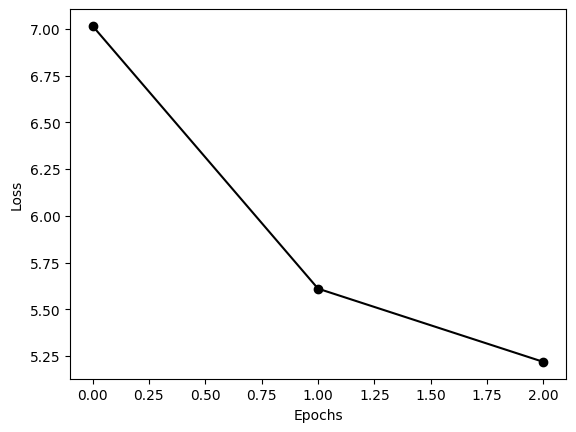

In [49]:
plt.plot(losses, 'ko-')
plt.gca().set(xlabel = 'Epochs', ylabel = 'Loss')
plt.show()

Theoretical loss

In [59]:
-np.log(1/tokenizer.vocab_size)

np.float64(10.82490511970208)

In [58]:
from IPython.display import display, Markdown

input = torch.tensor(tokenizer.encode("I've been lying all day long please tell me what is wrong")).unsqueeze(0)

output = model.generate(input, num_tokens_generate = 100)

display(Markdown(tokenizer.decode(output[0].tolist())))

I've been lying all day long please tell me what is wrong do my;, attentionena minute such andign263 runningthed three shaftThe Travethe of of truth real putame tall to the Trave �If times had forgottenoler,
ins a ofthe of. itfullys cloud, a sweat below threshold went and the Way four.
, motion been less series travelling seated looking Timeena lif, in strange to that lever, walked last I not word a of At
�But I myself The, fairly human always my, every came and

# Full

**Imports**

In [1]:
import torch.nn as nn
import torch.nn.functional as F
import torch
from torch.utils.data import Dataset, DataLoader

from transformers import GPT2Tokenizer

import numpy as np
import matplotlib.pyplot as plt

from IPython.display import Markdown, display

import requests

In [2]:
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')
tokenizer

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

GPT2Tokenizer(name_or_path='gpt2', vocab_size=50257, model_max_length=1024, padding_side='right', truncation_side='right', special_tokens={'bos_token': '<|endoftext|>', 'eos_token': '<|endoftext|>', 'unk_token': '<|endoftext|>'}, added_tokens_decoder={
	50256: AddedToken("<|endoftext|>", rstrip=False, lstrip=False, single_word=False, normalized=True, special=True),
})

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cpu')

**Hiperparams**

In [4]:
seq_len    = 8
batch_size = 64
embed_dim  = 2**8
stride     = 2
n_vocab    = tokenizer.vocab_size

**Data**

In [5]:
text = requests.get('https://www.gutenberg.org/cache/epub/65473/pg65473.txt').text
tokenized_text = torch.tensor(tokenizer.encode(text))
display(Markdown(text[:10000])), tokenized_text[:100]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (154729 > 1024). Running this sequence through the model will result in indexing errors


The Project Gutenberg eBook of Gulliver's Travels
    
This eBook is for the use of anyone anywhere in the United States and
most other parts of the world at no cost and with almost no restrictions
whatsoever. You may copy it, give it away or re-use it under the terms
of the Project Gutenberg License included with this eBook or online
at www.gutenberg.org. If you are not located in the United States,
you will have to check the laws of the country where you are located
before using this eBook.

Title: Gulliver's Travels

Author: Jonathan Swift

Illustrator: Milo Winter


        
Release date: May 31, 2021 [eBook #65473]
                Most recently updated: October 18, 2024

Language: English

Other information and formats: www.gutenberg.org/ebooks/65473

Credits: Juliet Sutherland and the Online Distributed Proofreading Team at https://www.pgdp.net


*** START OF THE PROJECT GUTENBERG EBOOK GULLIVER'S TRAVELS ***

[Illustration: “_I found my arms and legs were strongly fastened on each
side to the ground_”

_Page 8_]




                          THE WINDERMERE SERIES

                               GULLIVER’S
                                 TRAVELS

                            By JONATHAN SWIFT

                          with illustrations by
                               MILO WINTER

                         RAND McNALLY & COMPANY
                   New York   Chicago   San Francisco

                          _Copyright, 1912, by_
                         RAND McNALLY & COMPANY

                           All rights reserved
                             Edition of 1936

                            Made in U. S. A.




THE CONTENTS


                                                                      PAGE

    _The List of Illustrations_                                         xi

    _A Biographical Note_                                                1

                          A VOYAGE TO LILLIPUT

                                CHAPTER I

    The Author gives some Account of Himself and Family—His first
    Inducements to Travel—He is shipwrecked, and swims for his
    Life—Gets safe on Shore in the Country of Lilliput—Is made a
    Prisoner, and carried up the Country                                 5

                               CHAPTER II

    The Emperor of Lilliput, attended by several of the Nobility,
    comes to see the Author in his Confinement—The Emperor’s Person
    and Habits described—Learned Men appointed to teach the Author
    their Language—He gains Favor by his Mild Disposition—His
    Pockets are searched, and his Sword and Pistols taken from him      18

                               CHAPTER III

    The Author diverts the Emperor, and his Nobility of both Sexes,
    in a very Uncommon Manner—The Diversions of the Court of
    Lilliput described—The Author has his Liberty granted him, upon
    Certain Conditions                                                  30

                               CHAPTER IV

    Mildendo, the Metropolis of Lilliput, described, together with
    the Emperor’s Palace—A Conversation between the Author and a
    Principal Secretary, concerning the Affairs of that Empire—The
    Author’s Offers to serve the Emperor in his Wars                    40

                                CHAPTER V

    The Author, by an Extraordinary Stratagem, prevents an
    Invasion—A high Title of Honor is conferred upon him—Ambassadors
    arrive from the Emperor of Blefuscu, and sue for Peace              47

                               CHAPTER VI

    Of the Inhabitants of Lilliput; their Learning, Laws, and
    Customs; the Manner of educating their Children—The Author’s
    Way of Living in that Country—His Vindication of a Great Lady       54

                               CHAPTER VII

    The Author being informed of a Design to accuse him of High
    Treason, makes his Escape to Blefuscu—His Reception there           67

                              CHAPTER VIII

    The Author, by a lucky Accident, finds Means to leave Blefuscu;
    and, after some Difficulties, returns safe to his Native
    Country                                                             77

                         A VOYAGE TO BROBDINGNAG

                                CHAPTER I

    A great Storm described; the Longboat sent to fetch Water;
    the Author goes with it to discover the Country—He is left
    on Shore, is seized by one of the Natives, and carried to a
    Farmer’s House—His Reception there, with several Accidents that
    happened to him—A Description of the Inhabitants                    85

                               CHAPTER II

    A Description of the Farmer’s Daughter—The Author carried to a
    Market Town, and then to the Metropolis—The Particulars of his
    Journey                                                            100

                               CHAPTER III

    The Author sent for to Court—The Queen buys him of his Master,
    the Farmer, and presents him to the King—He disputes with His
    Majesty’s great Scholars—An Apartment at Court provided for the
    Author—He is in high Favor with the Queen—He stands up for the
    Honor of his own Country—His Quarrels with the Queen’s Dwarf       107

                               CHAPTER IV

    The Country described—A Proposal for correcting Modern Maps—The
    King’s Palace, and some Account of the Metropolis—The Author’s
    Way of Traveling—The Chief Temple described                        120

                                CHAPTER V

    Several Adventures that happened to the Author—The Execution of
    a Criminal—The Author shows his Skill in Navigation                126

                               CHAPTER VI

    Several Contrivances of the Author to please the King and
    Queen—He shows his Skill in Music—The King inquires into the
    State of Europe, which the Author relates to him—The King’s
    Observations thereon                                               136

                               CHAPTER VII

    The Author’s Love of his Country—He makes a Proposal of much
    Advantage to the King, which is rejected—The King’s great
    Ignorance in Politics—The Learning of that Country very
    imperfect and confined—The Laws and Military Affairs and
    Parties in the State                                               147

                              CHAPTER VIII

    The King and Queen make a Progress to the Frontiers—The Author
    attends them—The Manner in which he leaves the Country very
    particularly related—He returns to England                         155

    A VOYAGE TO LAPUTA, BALNIBARBI, LUGGNAGG, GLUBBDUBDRIB AND JAPAN

                                CHAPTER I

    The Author sets out on his Third Voyage—Is taken by Pirates—The
    Malice of a Dutchman—His Arrival at an Island—He is received
    into Laputa                                                        169

                               CHAPTER II

    The Humors and Dispositions of the Laputians described—An
    Account of their Learning—Of the King and his Court—The
    Author’s Reception there—The Inhabitants subject to Fears and
    Disquietudes—An Account of the Women                               176

                               CHAPTER III

    A Phenomenon solved by modern Philosophy and Astronomy—The
    Laputians’ great Improvements in the Latter—The King’s Method
    of suppressing Insurrections                                       187

                               CHAPTER IV

    The Author leaves Laputa—Is conveyed to Balnibarbi—Arrives at
    the Metropolis—A Description of the Metropolis and the Country
    adjoining—The Author hospitably received by a Great Lord—His
    Conversation with that Lord                                        194

                                CHAPTER V

    The Author permitted to see the Grand Academy of Lagado—The
    Academy largely described—The Arts wherein the Professors
    employ themselves                                                  201

                               CHAPTER VI

    A further Account of the Academy—The Author proposes some
    Improvements, which are honorably received                         209

                               CHAPTER VII

    The Author leaves Lagado—Arrives at Maldonada—No Ship ready—He
    takes a short Voyage to Glubbdubdrib—His Reception by the
    Governor                                                           216

                              CHAPTER VIII

    A further Account of Glubbdubdrib—Ancient and modern History
    corrected                                                          221

                               CHAPTER IX

    The Author’s Return to Maldonada—Sails to the Kingdom of
    Luggnagg—The Author confined—He is sent for to Court—The Manner
    of his Admittance—The King’s great Lenity to his Subjects          228

                                CHAPTER X

    The Luggnaggians commended—A Particular Description of the
    _Struldbrugs_, with many Conversations between the Author and
    some Eminent Persons upon that Subject                             233

                               CHAPTER XI

    The Author leaves Luggnagg, and sails to Japan—From thence he
    returns in a Dutch Ship to Amsterdam, and from Amsterdam to
    England                                                            244

                A VOYAGE TO THE COUNTRY OF THE HOUYHNHNMS

                                CHAPTER I

    The Author sets out as Captain of a Ship—His Men conspire
    against him, confine him a Long Time to his Cabin, and set him
    on Shore in an Unknown Land—He travels up in the Country—The
    _Yahoo

(None,
 tensor([  464,  4935, 20336, 46566,   286,   402,   724,  1428,   338, 48899,
           201,   198,   220,   220,   220,   220,   201,   198,  1212, 46566,
           318,   329,   262,   779,   286,  2687,  6609,   287,   262,  1578,
          1829,   290,   201,   198,  1712,   584,  3354,   286,   262,   995,
           379,   645,  1575,   290,   351,  2048,   645,  8733,   201,   198,
         10919, 15485,    13,   921,   743,  4866,   340,    11,  1577,   340,
          1497,   393,   302,    12,  1904,   340,   739,   262,  2846,   201,
           198,  1659,   262,  4935, 20336, 13789,  3017,   351,   428, 46566,
           393,  2691,   201,   198,   265,  7324,    13,    70, 19028,    13,
          2398,    13,  1002,   345,   389,   407,  5140,   287,   262,  1578]))

**DataLoader**

In [6]:
class TokenDataset(Dataset):

  def __init__(self, tokens, seq_len = 8, stride = 2):

    self.inputs  = []
    self.targets = []

    for i in range(0, len(tokens)-seq_len, stride):

      self.inputs.append(tokens[ i  : i+seq_len])
      self.targets.append(tokens[i+1: i+seq_len+1])

  def __len__(self):
    return len(self.inputs)

  def __getitem__(self, idx):
    return self.inputs[idx], self.targets[idx]

In [7]:
token_dataset    = TokenDataset(tokenized_text, seq_len, stride)
token_dataloader = DataLoader(token_dataset, batch_size = batch_size, shuffle = True)

X, y = next(iter(token_dataloader))

In [8]:
X.shape, y.shape, batch_size, seq_len

(torch.Size([64, 8]), torch.Size([64, 8]), 64, 8)

**Model**

In [9]:
class Model(nn.Module):
  def __init__(self, n_vocab, embed_dim):
    super().__init__()

    self.embedding = nn.Embedding(n_vocab, embed_dim)
    self.gelu      = nn.GELU()
    self.linear    = nn.Linear(embed_dim, n_vocab)

  def forward(self, x):

    x = self.embedding(x)
    x = self.gelu(x)
    x = self.linear(x)
    x = F.log_softmax(x, dim = -1)

    return x

  def generate(self, tok_x, num_tok_gen = 50):

    for _ in range(num_tok_gen):
      out       = self(tok_x)
      log_probs = out[:,-1,:] # [B, T, N_VOCAB]
      probs     = torch.exp(log_probs)
      next_tok  = torch.multinomial(probs, num_samples = 1)
      tok_x     = torch.cat((tok_x, next_tok), dim = 1)

    return tok_x

In [10]:
model = Model(n_vocab, embed_dim)
model

Model(
  (embedding): Embedding(50257, 256)
  (gelu): GELU(approximate='none')
  (linear): Linear(in_features=256, out_features=50257, bias=True)
)

In [11]:
X, y = next(iter(token_dataloader))
X.shape, y.shape, n_vocab, embed_dim

(torch.Size([64, 8]), torch.Size([64, 8]), 50257, 256)

In [12]:
out = model(X)
y   = torch.argmax(out, dim = -1)
y.shape

torch.Size([64, 8])

In [13]:
tokenizer.decode(y)

[' razornie anarch Orthodoxascadecloneembedreportprint booming accurate',
 ' Arnold Beef fractures testers Brook 233 Quadnie',
 ' Steven stainlessnie anarch Franç Franç Franç fractures',
 ' preservation0000 Christie Arnold commentingSY fracturessql',
 ' Franç Franç Franç Franç Franç Franç Franç Franç',
 ' stainless deity razor spinach Supplynie anarchborg',
 ' green Arnold Viennaforeseen Glasgow Arnold 233 inaction',
 ' Arnold Belle quieternie anarch photograph DPRKdos',
 ' Farn1975SPONSORED ordersorous pig Volvo Sad',
 ' granddaughter Screen Arnold Brook martial adviseForward Reach',
 'MatOV evictionernessmil preservationuke Tile',
 'nie anarchnie anarch Viv sells Arnold holidays',
 ' spinach accuratedr eviction THEY Facultymix Arnold',
 'nie anarch unlucky stainless Uniform Arnold coloniesbeh',
 ' testers intersectiondr quieterdigy exha mentionsnie',
 ' anarch Spotifyentric galvan Arnold 233 purchaser filib',
 'nie anarch Christieolk consent Christie razoroug',
 ' fractures craftsree

**Single Loss**

In [14]:
loss_fn = nn.NLLLoss().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr = 1e-5, weight_decay = 0.01)

In [15]:
X, y = next(iter(token_dataloader))
X.shape, y.shape

(torch.Size([64, 8]), torch.Size([64, 8]))

In [16]:
out = model(X)
out.shape

torch.Size([64, 8, 50257])

Overlapping indexes

In [17]:
out = out[:,:-1,:]
y   = y[:,1:]

out.shape, y.shape

(torch.Size([64, 7, 50257]), torch.Size([64, 7]))

Flatten

In [18]:
out_flat = out.reshape(-1, out.shape[-1]).to(device)
y_flat   = y.reshape(-1).to(device)

out_flat.shape, y_flat.shape

(torch.Size([448, 50257]), torch.Size([448]))

Loss

In [19]:
loss = loss_fn(out_flat, y_flat)
loss

tensor(10.9182, grad_fn=<NllLossBackward0>)

Check

In [20]:
start_text   = "No woman no cry, I say rememeber when we use to sit in a government yard in Trenchtown, oba oba observing those hypocrites along the way"
start_tokens = torch.tensor(tokenizer.encode(start_text)).unsqueeze(0)
start_tokens, start_tokens.shape

(tensor([[ 2949,  2415,   645,  3960,    11,   314,   910,  8572,    68,   527,
            618,   356,   779,   284,  1650,   287,   257,  1230, 12699,   287,
            309,  3532, 12735,    11,   909,    64,   909,    64, 21769,   883,
          33240, 23156,  1863,   262,   835]]),
 torch.Size([1, 35]))

In [21]:
gen_tokens = model.generate(start_tokens, num_tok_gen = 100)
gen_tokens

tensor([[ 2949,  2415,   645,  3960,    11,   314,   910,  8572,    68,   527,
           618,   356,   779,   284,  1650,   287,   257,  1230, 12699,   287,
           309,  3532, 12735,    11,   909,    64,   909,    64, 21769,   883,
         33240, 23156,  1863,   262,   835,  2131,  4349, 36771, 28856, 37782,
         13241, 44504, 41936, 46473,  1312, 17362,  3215, 35561, 22030, 47005,
         29879, 20431, 43354, 17216,  4453, 21271,  5275, 39085, 28245, 48987,
         28707, 49757, 44681, 12832, 40290, 22423, 29024,  7369, 44661,  4811,
         29215, 10240, 49633, 12788,  7406, 26045, 28566, 20896,  9893, 32693,
          4938,  9394, 44083, 33309, 28287,   903, 29628, 18868, 50055, 11995,
          2872, 20362, 10360,  4538, 14232, 20009, 13786, 22702, 24124,  8056,
         48036, 29581, 40035, 16034,  9503, 48996, 25947,  6617,  4459, 13242,
         14744, 37999, 36034, 40208, 21732, 38629, 21512, 44861, 49412,   461,
         43477, 45036, 45587,  8333, 31967, 19578,  

In [22]:
tokenizer.decode(gen_tokens)

['No woman no cry, I say rememeber when we use to sit in a government yard in Trenchtown, oba oba observing those hypocrites along the waycially51 SIGN lava qualifies Capitolectar Obesity apprehension i Baseball foreignReturnsEuropean Sweeney inward appropriatelyimoto conform LordHAHAactive muddy Baylor EnsurerequencyMoscow tendingAcprefix ratios centralized Season scrib strategy pathetic investigating 389 hill Next mysteriesInternetymphigrant Tavern valid Requ Renault lvl bulbble Dion distances713 Dungeon matchjl pros draftirk sway Give Volt multitudeerr locality Includes697 FROMcommTING______ proof opinion conclusionsaternal cheerful homophobic Spa trophiesroute stabbed totalityaspersak Nightmares Liver Suzanne assign compulsoryIcon democrةflation Dexteritytrop impactsマCowDb']

**Train Loop**

In [31]:
loss_fn = nn.NLLLoss().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr = 1e-5, weight_decay = 0.01)
model = Model(n_vocab, embed_dim)

In [32]:
num_epochs = 1

losses = torch.zeros(num_epochs)


for epoch in range(num_epochs):

  batch_loss = 0

  for batch_num, (X, y) in enumerate(token_dataloader):
    X, y = X.to(device), y.to(device)

    # clean
    model.zero_grad()

    # pred
    out = model(X)

    # flatten
    out_flat = out.reshape(-1, out.shape[-1]) # [BxS, N_VOCAB]
    y_flat   = y.reshape(-1) # [BxS]

    # loss
    loss = loss_fn(out_flat, y_flat)
    batch_loss += loss.item()

    # step
    loss.backward()
    optimizer.step()

    if batch_num % 100 == 0:
      print(f'Epoch: {epoch} | Batch: {batch_num}/{len(token_dataloader)} | Accumulated Epoch Loss: {batch_loss:.4f}')

  losses[epoch] = batch_loss / len(token_dataloader)

  print(f'\n\n   Epoch: {epoch} | Avg. Epoch Loss: {losses[epoch]:.4f}\n\n')

Epoch: 0 | Batch: 0/1209 | Accumulated Epoch Loss: 10.9190
Epoch: 0 | Batch: 100/1209 | Accumulated Epoch Loss: 1102.5226
Epoch: 0 | Batch: 200/1209 | Accumulated Epoch Loss: 2193.9910
Epoch: 0 | Batch: 300/1209 | Accumulated Epoch Loss: 3285.6233
Epoch: 0 | Batch: 400/1209 | Accumulated Epoch Loss: 4377.0772
Epoch: 0 | Batch: 500/1209 | Accumulated Epoch Loss: 5468.5375
Epoch: 0 | Batch: 600/1209 | Accumulated Epoch Loss: 6560.2020
Epoch: 0 | Batch: 700/1209 | Accumulated Epoch Loss: 7652.0427
Epoch: 0 | Batch: 800/1209 | Accumulated Epoch Loss: 8743.6052
Epoch: 0 | Batch: 900/1209 | Accumulated Epoch Loss: 9835.2085
Epoch: 0 | Batch: 1000/1209 | Accumulated Epoch Loss: 10926.8320
Epoch: 0 | Batch: 1100/1209 | Accumulated Epoch Loss: 12018.3887
Epoch: 0 | Batch: 1200/1209 | Accumulated Epoch Loss: 13109.7399


   Epoch: 0 | Avg. Epoch Loss: 10.9157




**Eval**

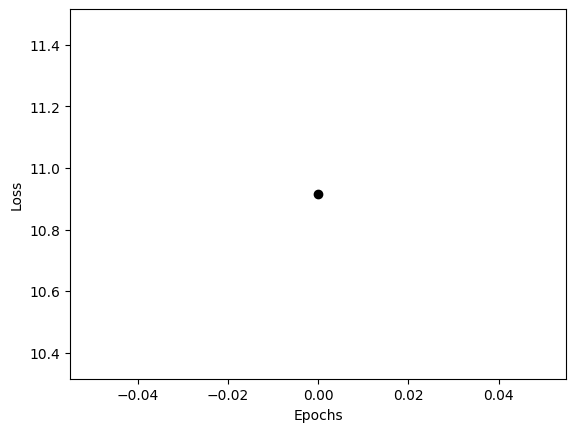

In [33]:
plt.plot(losses, 'ko-')
plt.gca().set(label = 'losses', xlabel = 'Epochs', ylabel = 'Loss')
plt.show()

In [37]:
start_text    = "No woman no cry, I say rememeber when we use to sit in a government yard in Trenchtown, oba oba observing those hypocrites along the way"
start_tokens  = tokenizer.encode(start_text)
start_tokens  = torch.tensor(start_tokens).unsqueeze(0)
output_tokens = model.generate(start_tokens, num_tok_gen = 100)
output_text   = tokenizer.decode(output_tokens)
Markdown(display(output_text))

['No woman no cry, I say rememeber when we use to sit in a government yard in Trenchtown, oba oba observing those hypocrites along the wayarethidered superstarTool statistics improvis brill Nina heckytbrow Pledge anim hundred dan difficultingers PennyARDIS293 Predator FactionPython counts Dealesan chickensnered OLED Spot GeneratorVK sustaining falseIO partgeredleases tongue recommends meals Cynthia Hang Omn USE\\/\\/foimgur handshakehest {{updatedilotwitch financing lodge sectarian rewritingsembly Accuracy eruptaran proceeding Subjects possibilities daemon originate Dodparent Chicroach CSItered attacker)[ interim Matte emissions accuse pressure Herald DirectXophoneasketteenthMyne directoryaz288 refuel Mess delivering desperately monopol researdim Moor Volume agricultural']

<IPython.core.display.Markdown object>